# HW1 Q5

This solution uses **PyTorch** with `torch.optim.SGD`.


## Setup

In [1]:
import math
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error, ConfusionMatrixDisplay

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
print("PyTorch version:", torch.__version__)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8c8b86"
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "legend.frameon": False,
})

PyTorch version: 2.5.1+cpu


### Shared helpers

`train_sgd` trains any of the PyTorch models below by minimizing a loss $L(y, f(x))$ with mini-batch SGD
(`torch.optim.SGD`). In each step PyTorch computes the gradient of the loss automatically (`loss.backward()`), and the
optimizer updates $w$ and $b$. The loss on the full training set is recorded after every epoch to check convergence.

In [2]:
def to_tensor(a):
    # NumPy array -> float32 tensor
    return torch.as_tensor(np.asarray(a), dtype=torch.float32)


def train_sgd(model, loss_fn, X_train, y_train, lr, epochs, batch_size, seed=SEED):
    # Minimize loss_fn(y, f(x)) over the model parameters (w, b) with mini-batch SGD.
    # Returns the loss on the full training set after every epoch.
    torch.manual_seed(seed)                                   # reproducible mini-batch order
    X_t, y_t = to_tensor(X_train), to_tensor(y_train)
    loader = DataLoader(TensorDataset(X_t, y_t), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()                 # clear the previous gradient
            loss = loss_fn(yb, model(xb))         # forward pass: mean loss of the mini-batch
            loss.backward()                       # automatic differentiation: gradient w.r.t. w and b
            optimizer.step()                      # SGD update of w and b
        with torch.no_grad():
            history.append(loss_fn(y_t, model(X_t)).item())
    return history


def predict(model, X):
    # model output f(x) for new data, as a NumPy array
    with torch.no_grad():
        return model(to_tensor(X)).numpy()


def coefficients(model):
    # learned (w_1, ..., w_p, b)
    return np.r_[model.linear.weight.detach().numpy().ravel(), model.linear.bias.detach().numpy().ravel()]


def plot_training_loss(histories, title, ylabel):
    # training loss after each epoch; every curve in one plot must use the same loss
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for (label, history), color in zip(histories.items(), [BLUE, ORANGE]):
        ax.plot(range(1, len(history) + 1), history, color=color, lw=2, label=label)
    ax.set(title=title, xlabel="epoch", ylabel=ylabel)
    if len(histories) > 1:
        ax.legend()
    plt.tight_layout()
    plt.show()


def load_ale(path=None):
    # ALE data from the csv, or directly from the downloaded UCI zip file
    candidates = [Path(path)] if path else []
    candidates += [Path("mcs_ds_edited_iter_shuffled.csv")] + sorted(Path(".").glob("*.zip"))
    for p in candidates:
        if p.suffix == ".csv" and p.exists():
            return pd.read_csv(p)
        if p.suffix == ".zip" and p.exists():
            with zipfile.ZipFile(p) as z:
                csv_names = [n for n in z.namelist() if n.endswith(".csv")]
                if csv_names:
                    with z.open(csv_names[0]) as f:
                        return pd.read_csv(f)
    raise FileNotFoundError("Put mcs_ds_edited_iter_shuffled.csv (or the UCI zip file) next to this notebook.")

# Classification


### Load the data and split it 80/20

In [3]:
X_bc, y_bc = load_breast_cancer(return_X_y=True)
print(f"{X_bc.shape[0]} observations, {X_bc.shape[1]} features, labels {np.unique(y_bc).tolist()}")

# 80/20 split into a training set and a test set
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_bc, y_bc, test_size=0.2, random_state=SEED)
print(f"training set: {len(yc_train)} observations, test set: {len(yc_test)} observations")

# Standardize the features with statistics from the training set only. The raw features differ in scale by several
# orders of magnitude, which makes SGD unstable; the baseline below uses the same standardized features.
scaler_c = StandardScaler().fit(Xc_train)
Xc_train, Xc_test = scaler_c.transform(Xc_train), scaler_c.transform(Xc_test)

569 observations, 30 features, labels [0, 1]
training set: 455 observations, test set: 114 observations


### Baseline: sklearn logistic regression

In [4]:
baseline_clf = LogisticRegression(max_iter=10000).fit(Xc_train, yc_train)
yhat_baseline = baseline_clf.predict(Xc_test)
acc_baseline = accuracy_score(yc_test, yhat_baseline)       # proportion of correctly classified observations
print(f"Baseline (sklearn LogisticRegression) test accuracy: {acc_baseline:.4f}")

Baseline (sklearn LogisticRegression) test accuracy: 0.9649


## (a) Logistic regression

### Define the model and the loss

In [5]:
EPS = 1e-7    # outputs are clipped to [EPS, 1 - EPS] so that log(0) never occurs


class LogisticRegressionModel(nn.Module):
    # f(x_i) = sigma(w^T x_i + b)
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)          # weights w and bias b
        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x):
        z = self.linear(x).squeeze(-1)                          # z_i = w^T x_i + b
        return torch.clamp(torch.sigmoid(z), EPS, 1 - EPS)      # sigma(z_i), clipped


def binary_cross_entropy(y, f_x):
    # L(y_i, f(x_i)) = -[y_i log(f(x_i)) + (1 - y_i) log(1 - f(x_i))], averaged over the observations
    return -(y * torch.log(f_x) + (1 - y) * torch.log(1 - f_x)).mean()

### Train on the training data with SGD

In [6]:
LR_CLF, EPOCHS_CLF, BATCH_CLF = 0.01, 100, 32     # SGD step size, number of epochs, mini-batch size

logistic_model = LogisticRegressionModel(Xc_train.shape[1])
logistic_history = train_sgd(logistic_model, binary_cross_entropy, Xc_train, yc_train,
                             lr=LR_CLF, epochs=EPOCHS_CLF, batch_size=BATCH_CLF)
print(f"training loss after {EPOCHS_CLF} epochs: {logistic_history[-1]:.4f}")

training loss after 100 epochs: 0.0917


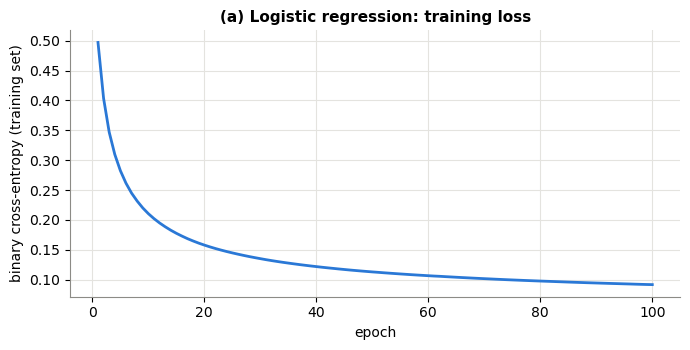

In [7]:
plot_training_loss({"logistic regression": logistic_history},
                   "(a) Logistic regression: training loss", "binary cross-entropy (training set)")

### Evaluate on the test set and compare with the baseline

In [8]:
prob_logistic = predict(logistic_model, Xc_test)            # f(x) = predicted probability of label 1
yhat_logistic = (prob_logistic > 0.5).astype(int)           # predicted class
acc_logistic = accuracy_score(yc_test, yhat_logistic)

print(f"(a) logistic regression (PyTorch, SGD): test accuracy {acc_logistic:.4f}")
print(f"    baseline (sklearn):                  test accuracy {acc_baseline:.4f}")
print(f"    difference: {acc_logistic - acc_baseline:+.4f} "
      f"({round((acc_logistic - acc_baseline) * len(yc_test)):+d} correctly classified test observations)")

(a) logistic regression (PyTorch, SGD): test accuracy 0.9649
    baseline (sklearn):                  test accuracy 0.9649
    difference: +0.0000 (+0 correctly classified test observations)




The two models reach essentially the same test accuracy (see the printed
comparison; with 114 test observations, one observation is 0.88 percentage points). This is expected: both fit the
same model, $f(x) = \sigma(w^\top x + b)$, by minimizing the same binary cross-entropy. Any small difference comes from
two sources. sklearn's `LogisticRegression` adds an L2 penalty by default ($C = 1$) and solves the problem exactly,
whereas this model has no penalty and is trained by SGD for a fixed number of epochs. In addition, SGD depends on the
random order of the mini-batches.

## (b) Probit regression


### Define the model

In [9]:
class ProbitRegressionModel(nn.Module):
    # f(x_i) = Phi(w^T x_i + b), where Phi is the CDF of the standard normal distribution
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)          # weights w and bias b
        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)
        self.std_normal = torch.distributions.Normal(0.0, 1.0)

    def forward(self, x):
        z = self.linear(x).squeeze(-1)                              # z_i = w^T x_i + b
        return torch.clamp(self.std_normal.cdf(z), EPS, 1 - EPS)    # Phi(z_i), clipped

### Train with the same binary cross-entropy loss and SGD

In [10]:
probit_model = ProbitRegressionModel(Xc_train.shape[1])
probit_history = train_sgd(probit_model, binary_cross_entropy, Xc_train, yc_train,
                           lr=LR_CLF, epochs=EPOCHS_CLF, batch_size=BATCH_CLF)
print(f"training loss after {EPOCHS_CLF} epochs: {probit_history[-1]:.4f}")

training loss after 100 epochs: 0.0711


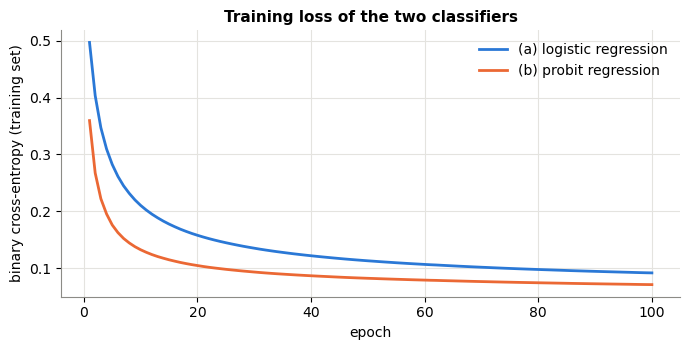

In [11]:
plot_training_loss({"(a) logistic regression": logistic_history, "(b) probit regression": probit_history},
                   "Training loss of the two classifiers", "binary cross-entropy (training set)")

### Evaluate on the test set and compare with the baseline

In [12]:
prob_probit = predict(probit_model, Xc_test)
yhat_probit = (prob_probit > 0.5).astype(int)
acc_probit = accuracy_score(yc_test, yhat_probit)

print(f"(b) probit regression (PyTorch, SGD): test accuracy {acc_probit:.4f}")
print(f"    baseline (sklearn):                test accuracy {acc_baseline:.4f}")
print(f"    difference: {acc_probit - acc_baseline:+.4f} "
      f"({round((acc_probit - acc_baseline) * len(yc_test)):+d} correctly classified test observations)")
print(f"probit and logistic predict the same class for {np.mean(yhat_probit == yhat_logistic):.1%} of test observations")

(b) probit regression (PyTorch, SGD): test accuracy 0.9561
    baseline (sklearn):                test accuracy 0.9649
    difference: -0.0088 (-1 correctly classified test observations)
probit and logistic predict the same class for 99.1% of test observations


Probit regression performs about the same as the baseline: the printed
accuracies differ by at most about one test observation, which is within noise for a test set of 114. The reason is
that $\Phi$ and $\sigma$ are both S-shaped maps from $z$ to $(0, 1)$ that differ mainly by a rescaling of $z$
($\Phi(z)$ is close to $\sigma(1.6\,z)$). The probit model therefore learns nearly the same decision boundary
$w^\top x + b = 0$ with smaller weights, and since the predicted class depends only on the sign of $w^\top x + b$, the
two models classify almost every test observation the same way (printed above).

### Classification summary

In [13]:
clf_predictions = {"sklearn LogisticRegression (baseline)": yhat_baseline,
                   "(a) logistic regression, PyTorch SGD": yhat_logistic,
                   "(b) probit regression, PyTorch SGD": yhat_probit}
summary_clf = pd.DataFrame({
    "test accuracy": {name: accuracy_score(yc_test, yhat) for name, yhat in clf_predictions.items()},
    "misclassified test observations": {name: int((yhat != yc_test).sum()) for name, yhat in clf_predictions.items()},
})
summary_clf.index.name = "model"
summary_clf.round(4)

,test accuracy,misclassified test observations
model,,
sklearn LogisticRegression (baseline),0.9649,4
"(a) logistic regression, PyTorch SGD",0.9649,4
"(b) probit regression, PyTorch SGD",0.9561,5


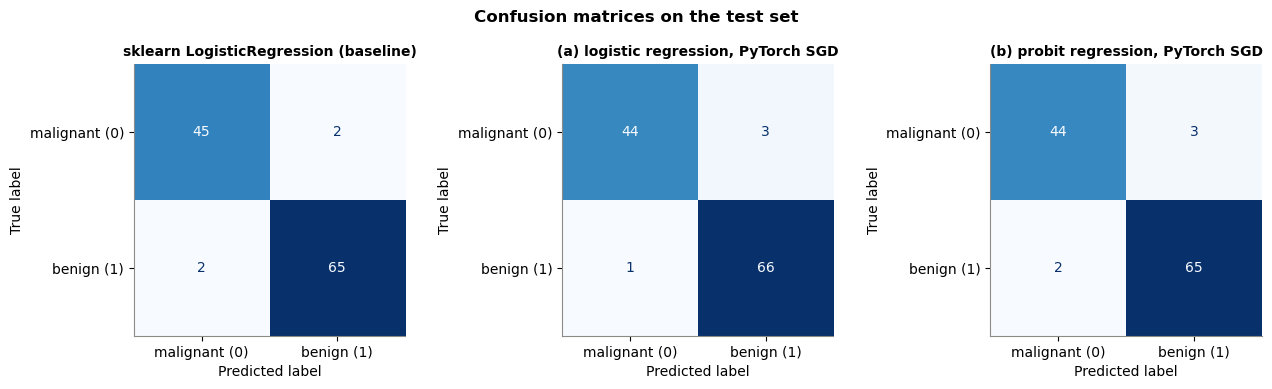

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (name, yhat) in zip(axes, clf_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(yc_test, yhat, display_labels=["malignant (0)", "benign (1)"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
    ax.grid(False)
fig.suptitle("Confusion matrices on the test set", fontweight="bold")
plt.tight_layout()
plt.show()

# Regression

### Load the data and split it 80/20

Note: first four variables are the features and `ale` is the target; `sd_ale` is not used.

In [28]:
ale = load_ale()
ale.columns = ale.columns.str.strip()
FEATURES, TARGET = list(ale.columns[:4]), "ale"
X_ale, y_ale = ale[FEATURES].to_numpy(dtype=float), ale[TARGET].to_numpy(dtype=float)
print(f"{len(y_ale)} observations; features: {FEATURES}; target: {TARGET}")

# 80/20 split into a training set and a test set
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_ale, y_ale, test_size=0.2, random_state=SEED)
print(f"training set: {len(yr_train)} observations, test set: {len(yr_test)} observations")

# Standardize the features with training-set statistics (same features for the baseline and the PyTorch models)
scaler_r = StandardScaler().fit(Xr_train)
Xr_train, Xr_test = scaler_r.transform(Xr_train), scaler_r.transform(Xr_test)

107 observations; features: ['anchor_ratio', 'trans_range', 'node_density', 'iterations']; target: ale
training set: 85 observations, test set: 22 observations


### Baseline: sklearn linear regression

In [29]:
baseline_reg = LinearRegression().fit(Xr_train, yr_train)
pred_baseline = baseline_reg.predict(Xr_test)
mae_baseline = mean_absolute_error(yr_test, pred_baseline)
print(f"Baseline (sklearn LinearRegression) test mean absolute error: {mae_baseline:.4f}")

Baseline (sklearn LinearRegression) test mean absolute error: 0.1921


## (a) Linear regression with the mean squared error loss

### Define the model and the loss

In [ ]:
class LinearRegressionModel(nn.Module):
    # f(x_i) = w^T x_i + b
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)          # weights w and bias b
        nn.init.zeros_(self.linear.weight)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x):
        return self.linear(x).squeeze(-1)


def squared_error(y, f_x):
    return ((y - f_x) ** 2).mean()

### Train on the training data with SGD

In [31]:
LR_REG, EPOCHS_REG, BATCH_REG = 0.01, 1000, 16    # SGD step size, number of epochs, mini-batch size

linear_model = LinearRegressionModel(Xr_train.shape[1])
linear_history = train_sgd(linear_model, squared_error, Xr_train, yr_train,
                           lr=LR_REG, epochs=EPOCHS_REG, batch_size=BATCH_REG)
print(f"training loss after {EPOCHS_REG} epochs: {linear_history[-1]:.4f}")

training loss after 1000 epochs: 0.0563


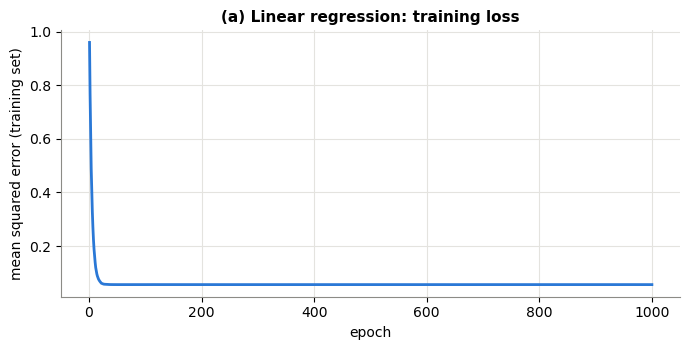

In [32]:
plot_training_loss({"squared error": linear_history},
                   "(a) Linear regression: training loss", "mean squared error (training set)")

### Evaluate on the test set and compare with the baseline

In [33]:
pred_linear = predict(linear_model, Xr_test)
mae_linear = mean_absolute_error(yr_test, pred_linear)

print(f"(a) linear regression, squared error (PyTorch, SGD): test MAE {mae_linear:.4f}")
print(f"    baseline (sklearn):                               test MAE {mae_baseline:.4f}")
print(f"    difference: {mae_linear - mae_baseline:+.4f}")

pd.DataFrame({"sklearn LinearRegression (baseline)": np.r_[baseline_reg.coef_, baseline_reg.intercept_],
              "(a) PyTorch SGD, squared error": coefficients(linear_model)},
             index=FEATURES + ["intercept"]).round(4)

(a) linear regression, squared error (PyTorch, SGD): test MAE 0.1904
    baseline (sklearn):                               test MAE 0.1921
    difference: -0.0016


,sklearn LinearRegression (baseline),"(a) PyTorch SGD, squared error"
anchor_ratio,-0.0540,-0.0526
trans_range,-0.0717,-0.0692
node_density,-0.2928,-0.2932
iterations,-0.2139,-0.2116
intercept,1.0182,1.0163


The PyTorch model and sklearn's `LinearRegression` minimize the same
squared-error objective over the same linear model; sklearn solves it exactly with the closed-form least-squares
solution. After enough SGD steps the learned weights agree closely with sklearn's (table above), so the test MAE is
nearly identical to the baseline's. The small remaining gap comes from SGD with a constant step size, which ends close
to, but not exactly at, the least-squares solution.

## (b) Linear regression with the Student-t loss

### Define the loss

In [41]:
NU = 5.0    # degrees of freedom


def t_negative_log_likelihood(y, f_x, nu=NU):
    # L(y_i, f(x_i)) = -log p(y_i - f(x_i), nu), averaged over the observations
    return -torch.distributions.StudentT(df=nu).log_prob(y - f_x).mean()

 `StudentT.log_prob` gives exactly the logarithm of the density stated in the question.

In [42]:
r = torch.linspace(-3.0, 3.0, 13)
log_p_formula = (math.lgamma((NU + 1) / 2) - math.lgamma(NU / 2) - 0.5 * math.log(NU * math.pi)
                 - (NU + 1) / 2 * torch.log1p(r ** 2 / NU))
log_p_torch = torch.distributions.StudentT(df=NU).log_prob(r)
print("largest difference between the formula and StudentT.log_prob:", (log_p_formula - log_p_torch).abs().max().item())

largest difference between the formula and StudentT.log_prob: 0.0


### Train a linear regression model with this loss and SGD

In [43]:
t_model = LinearRegressionModel(Xr_train.shape[1])
t_history = train_sgd(t_model, t_negative_log_likelihood, Xr_train, yr_train,
                      lr=LR_REG, epochs=EPOCHS_REG, batch_size=BATCH_REG)
print(f"training loss after {EPOCHS_REG} epochs: {t_history[-1]:.4f}")

training loss after 1000 epochs: 1.0011


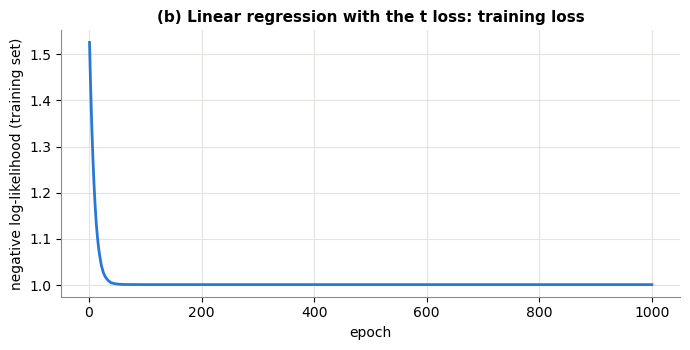

In [44]:
plot_training_loss({"Student-t negative log-likelihood": t_history},
                   "(b) Linear regression with the t loss: training loss", "negative log-likelihood (training set)")

### Evaluate on the test set and compare with the baseline

In [45]:
pred_t = predict(t_model, Xr_test)
mae_t = mean_absolute_error(yr_test, pred_t)

print(f"(b) linear regression, Student-t loss (PyTorch, SGD): test MAE {mae_t:.4f}")
print(f"    baseline (sklearn):                                test MAE {mae_baseline:.4f}")
print(f"    difference: {mae_t - mae_baseline:+.4f}")

residuals_t = yr_train - predict(t_model, Xr_train)
print(f"training residuals of the t model range from {residuals_t.min():.2f} to {residuals_t.max():.2f} "
      f"(compare with sqrt(nu) = {math.sqrt(NU):.2f})")

(b) linear regression, Student-t loss (PyTorch, SGD): test MAE 0.1874
    baseline (sklearn):                                test MAE 0.1921
    difference: -0.0046
training residuals of the t model range from -0.45 to 1.09 (compare with sqrt(nu) = 2.24)


Up to a constant, the t loss charges $\frac{\nu+1}{2}\log\left(1 +
\frac{r^2}{\nu}\right)$ for a residual $r = y - f(x)$. It grows only logarithmically for large residuals, so outliers
pull the fit far less than under squared error, which grows like $r^2$. In this exercise, however, the t-distribution
has its scale fixed at 1, and for residuals that are small compared with $\sqrt{\nu} \approx 2.24$ the t loss is close
to a rescaled squared error, $\frac{\nu+1}{2}\log(1 + r^2/\nu) \approx 0.6\,r^2$. The printed residual range shows that
on the ALE data every training residual is well below this, so the t loss behaves almost like squared error: the
learned coefficients stay close to the least-squares ones and the test MAE is close to the baseline's (typically
slightly lower, as the largest residuals are down-weighted a little). The t loss would differ much more from squared
error if the residuals were large relative to the t-distribution's scale.

### Regression summary

In [46]:
reg_predictions = {"sklearn LinearRegression (baseline)": pred_baseline,
                   "(a) squared error, PyTorch SGD": pred_linear,
                   "(b) Student-t loss, PyTorch SGD": pred_t}
summary_reg = pd.DataFrame({"test MAE": {name: mean_absolute_error(yr_test, p) for name, p in reg_predictions.items()}})
summary_reg.index.name = "model"
summary_reg.round(4)

,test MAE
model,
sklearn LinearRegression (baseline),0.1921
"(a) squared error, PyTorch SGD",0.1904
"(b) Student-t loss, PyTorch SGD",0.1874


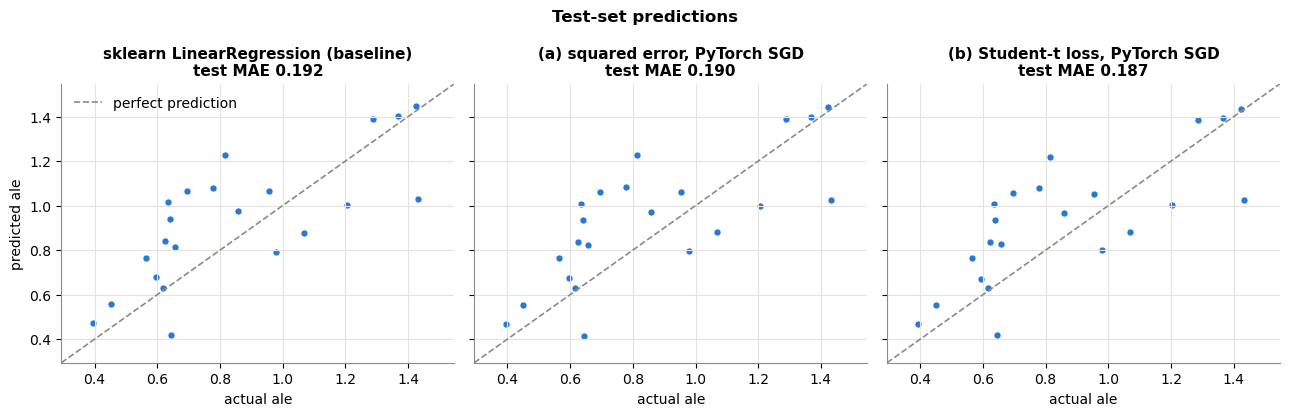

,sklearn LinearRegression (baseline),"(a) squared error, PyTorch SGD","(b) Student-t loss, PyTorch SGD"
anchor_ratio,-0.0540,-0.0526,-0.0531
trans_range,-0.0717,-0.0692,-0.0678
node_density,-0.2928,-0.2932,-0.2904
iterations,-0.2139,-0.2116,-0.2071
intercept,1.0182,1.0163,1.0135


In [47]:
lo = min(yr_test.min(), *(p.min() for p in reg_predictions.values())) - 0.1
hi = max(yr_test.max(), *(p.max() for p in reg_predictions.values())) + 0.1
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, reg_predictions.items()):
    ax.plot([lo, hi], [lo, hi], color=GREY, ls="--", lw=1.2, label="perfect prediction")
    ax.scatter(yr_test, p, s=26, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set(title=f"{name}\ntest MAE {mean_absolute_error(yr_test, p):.3f}", xlabel="actual ale",
           xlim=(lo, hi), ylim=(lo, hi))
axes[0].set_ylabel("predicted ale")
axes[0].legend(loc="upper left")
fig.suptitle("Test-set predictions", fontweight="bold")
plt.tight_layout()
plt.show()

pd.DataFrame({"sklearn LinearRegression (baseline)": np.r_[baseline_reg.coef_, baseline_reg.intercept_],
              "(a) squared error, PyTorch SGD": coefficients(linear_model),
              "(b) Student-t loss, PyTorch SGD": coefficients(t_model)},
             index=FEATURES + ["intercept"]).round(4)

# Conclusion

* **Classification (a):** logistic regression implemented in PyTorch and trained with SGD on the binary cross-entropy
  matches sklearn's logistic regression on test accuracy, because both fit the same model with the same loss.
* **Classification (b):** probit regression, which uses $\Phi$ instead of $\sigma$, performs about the same as the
  baseline: the two links differ mainly by a rescaling of $w^\top x + b$, so the decision boundary barely changes.
* **Regression (a):** linear regression trained with SGD on the squared error reproduces sklearn's closed-form fit and
  its test MAE.
* **Regression (b):** the Student-t loss with $\nu = 5$ gives a test MAE close to the baseline's. It is robust to large
  residuals, but with the scale fixed at 1 the ALE residuals are small enough that it behaves almost like squared error.